# Balance Lab: simulating a robot that must not fall

A hands-on companion to the video **"Why Robots Fall Over: Balance as a Control Problem"** (Concepts Mentor on YouTube). Run the cells **from top to bottom** (Shift + Enter).
Each part adds **one idea** and ends with **"Try this"** suggestions. Change a number, run the cell again, and see what happens.

| Part | Idea |
|---|---|
| 1 | The model: a weight on a stick (the inverted pendulum) |
| 2 | No control: how fast it falls |
| 3 | Open loop: a perfect plan, then a push |
| 4 | Closed loop: measure and correct (and why "feet under the body" is not enough) |
| 5 | The push is a disturbance; the capture point predicts the future |
| 6 | Limits: the feet are small (saturation) |
| 7 | Reaction delay, in the time domain |
| 8 | Gain vs delay: the stability map |
| 9 | The same story in the frequency domain (Bode plot, phase margin) |
| 10 | Taking a step |
| 11 | Playground |

**Honesty note:** this is a simple textbook model with **assumed parameters**. It explains ideas; it does not
describe any real robot or person.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# colours used in the video
CYAN, AMBER, RED, GREY, DARK = "#1BA9C9", "#E0901A", "#E05555", "#8A94A6", "#222831"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
print("ready")

ready


## Part 1: The model, a weight on a stick

Look at a standing body **from the front**. All of its mass is lumped into one point, the **centre of mass (CoM)**, at height
$z$. The feet push on the floor at one point: the **centre of pressure (CoP)**, $p$. The stick joins the two.

**Where the equation comes from (Newton, one line).** When the mass is to the side of the push point, the stick leans.
The leg force has to hold up the weight $m g$, so it also gets a sideways part, the weight times the lean. For a small
lean, the lean is $(x - p)/z$:

$$m\,\ddot{x} = m\,g\,\frac{x - p}{z} \quad\Rightarrow\quad \boxed{\ddot{x} = \omega^2\,(x - p), \qquad \omega = \sqrt{g / z}}$$

This is the **linear inverted pendulum**. Its assumptions, stated plainly:
1. the lean is small (so "lean ≈ (x − p)/z"),
2. the height $z$ of the mass stays **roughly constant**, so $\omega$ is a **constant** and the equation is linear,
3. we only look at one direction (sideways, seen from the front).

**Sign convention:** positive $x$ = to the right, on every plot (the video uses the same convention).

In words: **the mass accelerates away from the point where the feet push.** The further it is from that point, the
faster it accelerates. That is exactly why it is *unstable*.

- $x$: where the mass is (sideways, metres)
- $p$: where the feet push (the only thing the robot can control, and only **inside the feet**)
- $\omega$: how "fast" this pendulum is. A taller body has a smaller $\omega$, so it takes longer to fall.
- $z = 1$ m here: an **assumed**, round number for a person-sized robot.

In [2]:
g = 9.81          # gravity, m/s^2
z = 1.0           # height of the centre of mass, m (assumed, a round number for a person-sized robot)
omega = np.sqrt(g / z)
dt = 0.001        # simulation time step, s (1 ms)

print(f"omega = {omega:.2f} 1/s")

def lip_step(x, v, p):
    # one 1-ms step of the linear inverted pendulum (simple Euler integration)
    a = omega**2 * (x - p)     # the whole physics is this line
    v = v + a * dt
    x = x + v * dt
    return x, v

omega = 3.13 1/s


## Part 2: No control, how fast does it fall?

Start the mass **1 cm** to the side of the feet, standing still, and do nothing ($p = 0$).

the lean doubles every 0.22 s
after 1 s: 12 cm, after 1.5 s: 55 cm


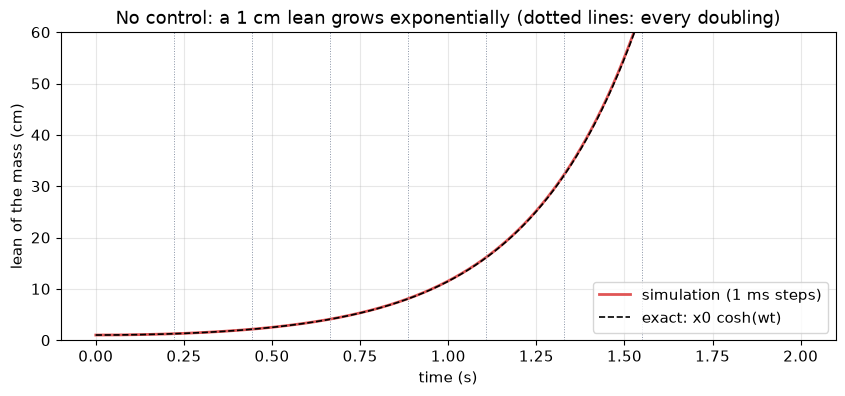

In [3]:
T = 2.0
t = np.arange(0, T, dt)
x, v = 0.01, 0.0                     # 1 cm lean, not moving
xs = []
for _ in t:
    x, v = lip_step(x, v, p=0.0)     # feet push at 0, always
    xs.append(x)
xs = np.array(xs)

doubling = np.log(2) / omega
print(f"the lean doubles every {doubling:.2f} s")
print(f"after 1 s: {xs[int(1/dt)]*100:.0f} cm, after 1.5 s: {xs[int(1.5/dt)]*100:.0f} cm")

x_exact = 0.01 * np.cosh(omega * t)          # exact solution for p = 0, starting at rest
plt.plot(t, xs * 100, color=RED, lw=2, label="simulation (1 ms steps)")
plt.plot(t, x_exact * 100, "k--", lw=1.2, label="exact: x0 cosh(wt)")
plt.legend()
for k in range(1, 8):
    plt.axvline(k * doubling, color=GREY, lw=0.7, ls=":")
plt.xlabel("time (s)"); plt.ylabel("lean of the mass (cm)")
plt.title("No control: a 1 cm lean grows exponentially (dotted lines: every doubling)")
plt.ylim(0, 60); plt.show()

**What you just saw:** the error does not grow steadily, it grows **exponentially**. With $p = 0$ and starting at rest,
the equation $\ddot{x} = \omega^2 x$ has the exact solution

$$\boxed{x(t) = x_0 \cosh(\omega t) \approx \tfrac{1}{2}\,x_0\,e^{\omega t}} \qquad\Rightarrow\qquad
\text{doubling time} = \frac{\ln 2}{\omega} \approx 0.22\ \text{s}$$

The further it leans, the harder gravity pulls it sideways, so the lean grows faster and faster. The dashed exact curve
sits on top of the simulation: a good check that the 1 ms simulation steps are small enough.
That is the signature of an **unstable** system (mathematically: a pole at $s = +\omega$).

**Try this:** set `z = 0.10` (a pencil on its tip) or `z = 1.5` (a broom) in Part 1 and run Parts 1–2 again.
A broom falls much more slowly. That is why you can balance a broom on your hand, but not a pencil.

## Part 3: Open loop, a perfect plan and then a push

**Open loop** means the robot follows a plan and never looks at what actually happens.

The perfect plan for standing still is trivial: keep the feet pushing right under the mass, $p = 0$. If nothing goes wrong,
the robot stands forever. Now give it a small **push** at $t = 1$ s: a sudden sideways speed of 0.1 m/s.

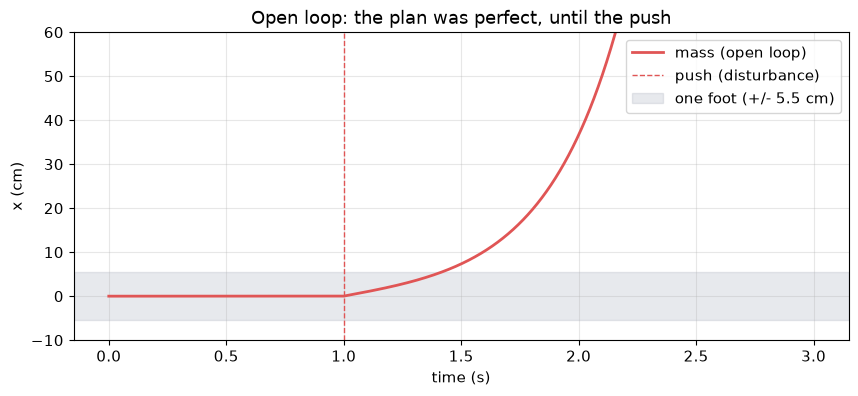

In [4]:
T = 3.0
t = np.arange(0, T, dt)
x, v = 0.0, 0.0
xs = []
for ti in t:
    if abs(ti - 1.0) < dt / 2:
        v += 0.1                     # the push: +0.1 m/s, instantly
    x, v = lip_step(x, v, p=0.0)     # open loop: the plan says p = 0, whatever happens
    xs.append(x)
xs = np.array(xs)

plt.plot(t, xs * 100, color=RED, lw=2, label="mass (open loop)")
plt.axvline(1.0, color=RED, ls="--", lw=1, label="push (disturbance)")
plt.axhspan(-5.5, 5.5, color=GREY, alpha=0.2, label="one foot (+/- 5.5 cm)")
plt.xlabel("time (s)"); plt.ylabel("x (cm)"); plt.ylim(-10, 60); plt.legend()
plt.title("Open loop: the plan was perfect, until the push"); plt.show()

**Insight:** for an **unstable** system, open loop cannot work: any disturbance, or even a 1 mm error in the plan,
grows by itself. Balance **needs feedback**.

## Part 4: Closed loop, measure and correct

**Closed loop** means: **measure** the state → **compare** with the goal (upright) → **correct** with the feet.

```
 push (disturbance) ──►(+)──► BODY (pendulum) ──► x, v ──┐
                       ▲                                 │
                       └── FEET (CoP p) ◄── CONTROLLER ◄─┘ (sensors)
```

**First idea (it seems obvious): keep the feet right under the mass:** $p = x$.

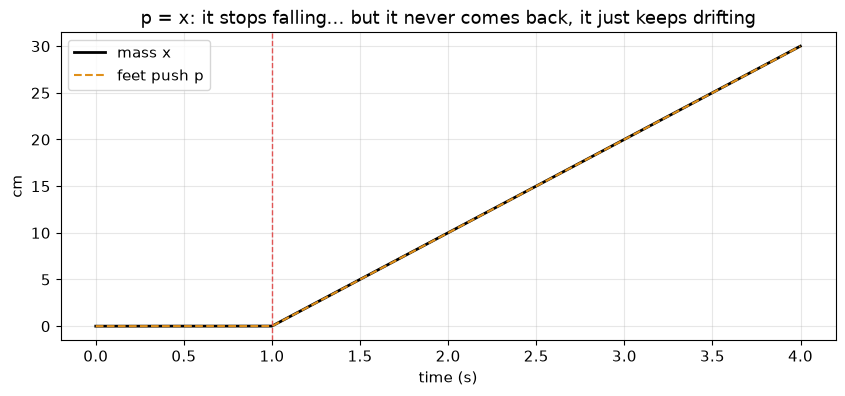

In [5]:
def run(controller, push=0.1, T=4.0):
    t = np.arange(0, T, dt)
    x, v = 0.0, 0.0
    X, P = [], []
    for ti in t:
        if abs(ti - 1.0) < dt / 2:
            v += push
        p = controller(x, v)
        x, v = lip_step(x, v, p)
        X.append(x); P.append(p)
    return t, np.array(X), np.array(P)

t, X, P = run(lambda x, v: x)        # "feet under the mass"
plt.plot(t, X * 100, color="k", lw=2, label="mass x")
plt.plot(t, P * 100, color=AMBER, lw=1.5, ls="--", label="feet push p")
plt.axvline(1.0, color=RED, ls="--", lw=1)
plt.xlabel("time (s)"); plt.ylabel("cm"); plt.legend()
plt.title("p = x: it stops falling... but it never comes back, it just keeps drifting"); plt.show()

With $p = x$ the acceleration is zero, so the mass **keeps the speed the push gave it** and drifts away forever.
To *stop and come back*, the feet must push **beyond** the mass, on the side it is moving to.

How far beyond? That is the **capture point**:

$$\xi = x + \frac{v}{\omega}$$

It is the spot where, if the feet pushed there, the mass would come to rest exactly above it.
(Research: Pratt et al. 2006, "Capture Point". Human-balance researchers call the same quantity the *extrapolated centre of mass*.)

**Capture-point controller:** push a bit beyond the capture point, with a gain $k$:

$$p = \xi + k\,\xi$$

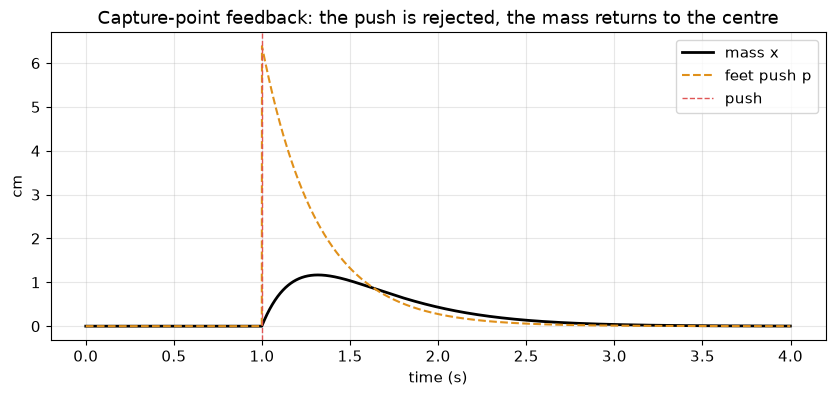

largest CoP excursion: 6.4 cm


In [6]:
def capture_point(x, v):
    return x + v / omega

k = 1.0
t, X, P = run(lambda x, v: capture_point(x, v) * (1 + k))
plt.plot(t, X * 100, color="k", lw=2, label="mass x")
plt.plot(t, P * 100, color=AMBER, lw=1.5, ls="--", label="feet push p")
plt.axvline(1.0, color=RED, ls="--", lw=1, label="push")
plt.xlabel("time (s)"); plt.ylabel("cm"); plt.legend()
plt.title("Capture-point feedback: the push is rejected, the mass returns to the centre"); plt.show()
print(f"largest CoP excursion: {abs(P).max()*100:.1f} cm")

**What you just saw:** the feet first push **ahead** of the mass (the amber spike), which brakes it, and then
bring it back. Notice how big that spike is; Part 6 will show why it matters.

**Try this:** change `k` to 0.3 and to 3. A small gain is slow and lazy; a big gain is fast, but needs a big CoP excursion.

## Part 5: The push is a disturbance; the capture point predicts the future

In control language, the push is a **disturbance**: an input nobody chose, which the loop must **reject**.
This one is an *impulse* disturbance: it changes the speed instantly, not the position.

The capture point reacts **at once**, while the mass has hardly moved. It is a prediction of where the body is heading.

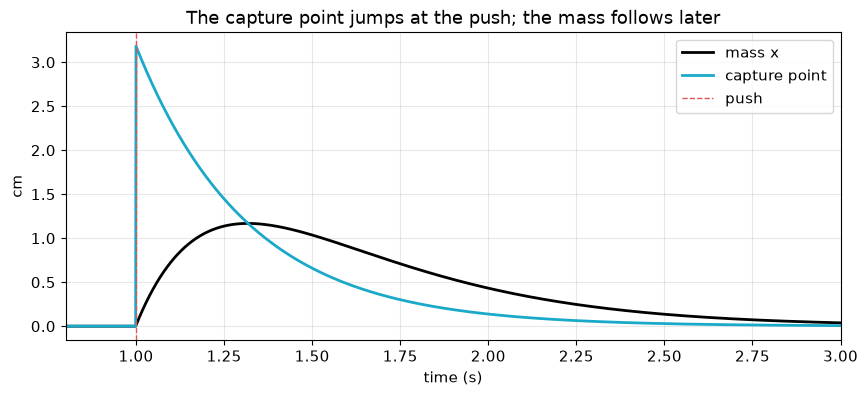

a push of 0.1 m/s moves the capture point by 3.2 cm instantly


In [7]:
t = np.arange(0, 3.0, dt)
x, v = 0.0, 0.0
X, XI = [], []
for ti in t:
    if abs(ti - 1.0) < dt / 2:
        v += 0.1
    x, v = lip_step(x, v, (1 + k) * capture_point(x, v))
    X.append(x); XI.append(capture_point(x, v))
plt.plot(t, np.array(X) * 100, color="k", lw=2, label="mass x")
plt.plot(t, np.array(XI) * 100, color=CYAN, lw=2, label="capture point")
plt.axvline(1.0, color=RED, ls="--", lw=1, label="push")
plt.xlim(0.8, 3); plt.xlabel("time (s)"); plt.ylabel("cm"); plt.legend()
plt.title("The capture point jumps at the push; the mass follows later"); plt.show()
print(f"a push of 0.1 m/s moves the capture point by {0.1/omega*100:.1f} cm instantly")

## Part 6: Limits, the feet are small (saturation)

The CoP can only be **inside the feet**. Seen from the front, "inside the feet" means from the **outer edge of the left
foot to the outer edge of the right foot**: feet 19 cm apart (centre to centre), each 11 cm wide, gives **±15 cm**
(assumed). It is a sideways width, not the length of a foot. The body shifts the CoP within it by moving pressure between
the edges of the soles and between the two feet; **the feet themselves do not move**.
Swinging the upper body (the hips) acts like a little extra push: we assume **6 cm** more, so ±21 cm in total. (In the
video's graphs: the dark band = feet, the light band = + hips.) Beyond that, the controller asks for something the body cannot do: the
command **saturates**.

Below, we let the controller ask for anything, but clip $p$ to the feet, and we try bigger and bigger pushes.

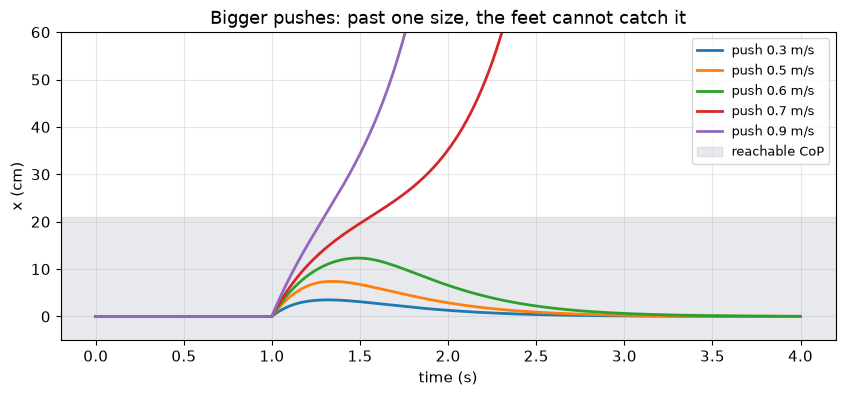

theory: largest push without a step = foot * omega = 0.66 m/s


In [8]:
FOOT = 0.15 + 0.06     # feet edge + hip help, m (assumed)

def run_sat(push, k=1.0, T=4.0, foot=FOOT):
    t = np.arange(0, T, dt)
    x, v = 0.0, 0.0
    X = []
    for ti in t:
        if abs(ti - 1.0) < dt / 2:
            v += push
        p = np.clip((1 + k) * capture_point(x, v), -foot, foot)   # saturation
        x, v = lip_step(x, v, p)
        X.append(x)
        if abs(x) > 1.0:            # fell
            break
    return t[:len(X)], np.array(X)

for push in [0.3, 0.5, 0.6, 0.7, 0.9]:
    t, X = run_sat(push)
    plt.plot(t, X * 100, lw=2, label=f"push {push} m/s")
plt.axhspan(-FOOT * 100, FOOT * 100, color=GREY, alpha=0.2, label="reachable CoP")
plt.ylim(-5, 60); plt.xlabel("time (s)"); plt.ylabel("x (cm)"); plt.legend(fontsize=9)
plt.title("Bigger pushes: past one size, the feet cannot catch it"); plt.show()

print(f"theory: largest push without a step = foot * omega = {FOOT*omega:.2f} m/s")

**Insight:** linear control theory assumes the actuator can do whatever it is asked. Real feet are small, so a large
enough push is **not recoverable by the ankles and hips at all**, however clever the controller. The rule is simple:
**if the capture point leaves the reachable CoP region, you must step** (Part 10).

## Part 7: Reaction delay, in the time domain

Sensors, computing and motors all take time. The controller acts on what the body **was** doing $\tau$ seconds ago.
We keep a short memory of past states and feed the controller the old one.

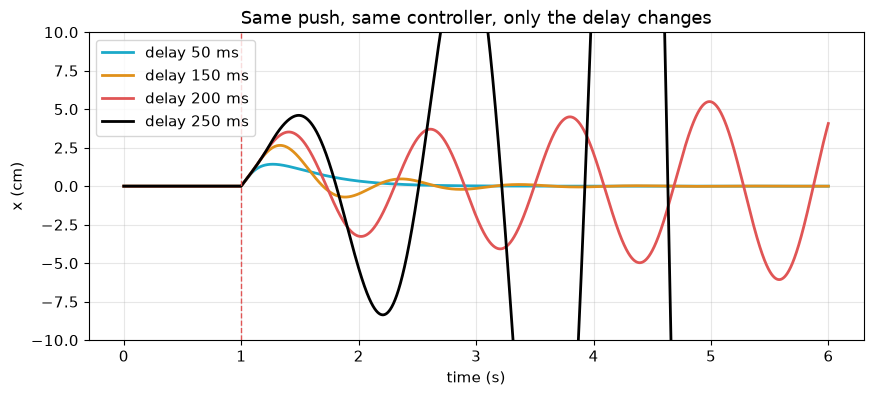

In [9]:
def simulate(push=0.1, k=1.0, delay=0.0, foot=None, T=4.0, t_push=1.0, x0=0.0):
    # closed loop with capture-point feedback, a reaction delay, and optional foot limits
    t = np.arange(0, T, dt)
    lag = int(round(delay / dt))
    x, v = x0, 0.0
    hist = []                       # past capture points (what the sensors reported)
    X, XI, P = [], [], []
    for ti in t:
        if abs(ti - t_push) < dt / 2:
            v += push
        hist.append(capture_point(x, v))
        xi_seen = hist[-1 - lag] if len(hist) > lag else hist[0]
        p = (1 + k) * xi_seen
        if foot is not None:
            p = np.clip(p, -foot, foot)
        x, v = lip_step(x, v, p)
        X.append(x); XI.append(capture_point(x, v)); P.append(p)
        if abs(x) > 1.0:
            break
    n = len(X)
    return t[:n], np.array(X), np.array(XI), np.array(P)

fig, ax = plt.subplots()
for d, c in [(0.05, CYAN), (0.15, AMBER), (0.20, RED), (0.25, "k")]:
    t, X, XI, P = simulate(push=0.1, delay=d, T=6)
    ax.plot(t, X * 100, color=c, lw=2, label=f"delay {d*1000:.0f} ms")
ax.axvline(1.0, color=RED, ls="--", lw=1)
ax.set_ylim(-10, 10); ax.set_xlabel("time (s)"); ax.set_ylabel("x (cm)"); ax.legend()
ax.set_title("Same push, same controller, only the delay changes"); plt.show()

**What you just saw:**
- **50 ms:** a calm return.
- **150 ms:** it overshoots and **rings** before settling.
- **200 ms:** the ringing **grows**: the correction always arrives too late and pushes the wrong way. The controller itself
  now makes things worse.

Delay can turn a stable feedback loop into an unstable one. That is the most important practical lesson in control.

**Try this:** find the delay where the ringing neither grows nor shrinks (between 150 and 200 ms).

**Try this too (nonlinear):** run `simulate(push=0.1, delay=0.22, foot=0.21, T=12)` and plot `X`. Linear theory
says 220 ms is unstable. Does the robot fall, or does the foot limit hold it in a steady wobble? Then try 0.25 and 0.30.
What changes when the actuator is saturated?

### Delay also shrinks the push you can survive

While the controller waits $\tau$ seconds, nothing corrects the body, and the capture point runs away:
$\xi(\tau) = \xi_0\,e^{\omega\tau}$. The feet can hold a capture point up to the edge $a$ (feet + hips), so the largest push
the ankles and hips can handle is

$$\boxed{\Delta v_{max} = a\,\omega\,e^{-\omega \tau}}$$

Let's check that formula against the simulation (bisection: the biggest push that does not fall).

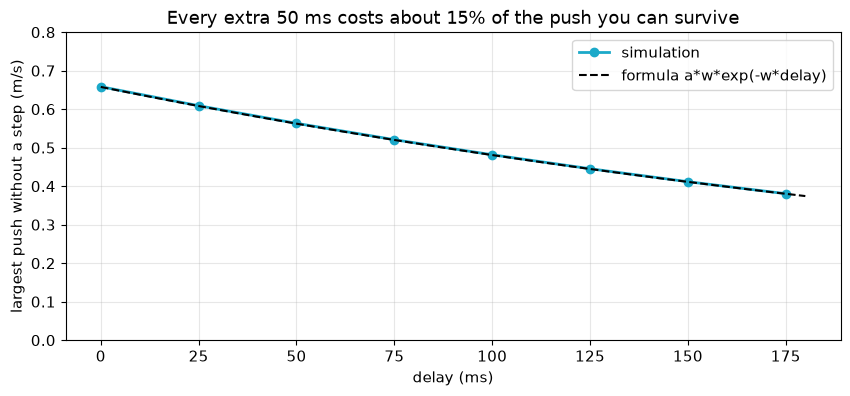

factor per extra 50 ms: 0.86


In [10]:
def survives(push, delay):
    t, X, XI, P = simulate(push=push, delay=delay, foot=FOOT, T=5)
    return len(X) == len(np.arange(0, 5, dt))

dls = np.arange(0, 0.176, 0.025)
largest = []
for d in dls:
    lo, hi = 0.0, 1.5
    for _ in range(12):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if survives(mid, d) else (lo, mid)
    largest.append(lo)

tf = np.linspace(0, 0.18, 100)
plt.plot(dls * 1000, largest, "o-", color=CYAN, lw=2, label="simulation")
plt.plot(tf * 1000, FOOT * omega * np.exp(-omega * tf), "k--", label="formula a*w*exp(-w*delay)")
plt.xlabel("delay (ms)"); plt.ylabel("largest push without a step (m/s)"); plt.ylim(0, 0.8); plt.legend()
plt.title("Every extra 50 ms costs about 15% of the push you can survive"); plt.show()
print(f"factor per extra 50 ms: {np.exp(-omega * 0.05):.2f}")

## Part 8: Gain vs delay, the stability map

Is a stronger correction (bigger $k$) always better? Let's map **stable / unstable** for many $k$ and delays by brute
force: simulate each pair and check whether the motion dies out.

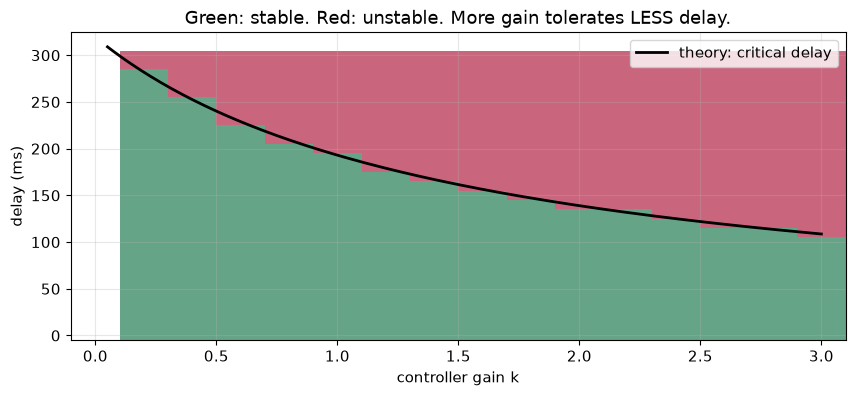

In [11]:
def is_stable(k, delay):
    t, X, XI, P = simulate(push=0.05, k=k, delay=delay, T=8)
    if len(X) < len(np.arange(0, 8, dt)):      # it fell
        return False
    early = np.abs(X[int(2 / dt):int(4 / dt)]).max()   # wobble between 2 s and 4 s
    late = np.abs(X[int(6 / dt):]).max()               # wobble between 6 s and 8 s
    return late < early                                # shrinking = stable

ks = np.linspace(0.2, 3.0, 15)
delays = np.linspace(0.0, 0.30, 31)     # every 10 ms (takes ~1 min)
grid = np.array([[is_stable(kk, d) for kk in ks] for d in delays])

# theory (derived in Part 9): the critical delay for gain k
k_fine = np.linspace(0.05, 3.0, 200)
W = omega * np.sqrt((1 + k_fine)**2 - 1)
tau_crit = np.arctan(W / omega) / W

plt.pcolormesh(ks, delays * 1000, grid, cmap="RdYlGn", shading="nearest", alpha=0.6)
plt.plot(k_fine, tau_crit * 1000, "k", lw=2, label="theory: critical delay")
plt.xlabel("controller gain k"); plt.ylabel("delay (ms)"); plt.legend()
plt.title("Green: stable. Red: unstable. More gain tolerates LESS delay."); plt.show()

**Insight:** the black line (theory) matches the simulation. A **stronger** correction makes the system **less tolerant
of delay**. With a slow nervous system or a slow robot, you must react **more gently**. Engineers trade speed against
robustness.

## Part 9: The same story in the frequency domain (optional, a bit deeper)

**Idea:** any motion can be seen as a mix of slow and fast wiggles (frequencies). For each frequency we ask two
questions about the loop *body → sensor → delay → controller → feet*:
- **gain:** how much does a wiggle get amplified once around the loop?
- **phase:** how late does it come back?

A delay of $\tau$ does not change the gain, but it adds a lag of $\Omega\tau$ radians, **more lag at higher frequencies**.

For our loop (capture-point dynamics $\dot\xi = \omega(\xi - p)$, controller $p = (1+k)\,\xi$ delayed), the loop transfer
function is

$$L(j\Omega) = \frac{\omega (1+k)\, e^{-j\Omega\tau}}{j\Omega - \omega}$$

The **crossover** is the frequency where the gain is 1. The **phase margin** is how far the phase is from the fatal
$-180°$ at crossover. When the margin reaches zero, the wiggle comes back exactly in step with itself and keeps
growing: instability.

(For an open-loop *unstable* body like ours, the full test is the Nyquist criterion. For this loop the margin
rule gives the same answer as the brute-force simulation in Part 8. That is a good habit: check theory with simulation.)

delay   50 ms: phase margin  44.5 deg
delay  150 ms: phase margin  13.4 deg
delay  193 ms: phase margin   0.0 deg


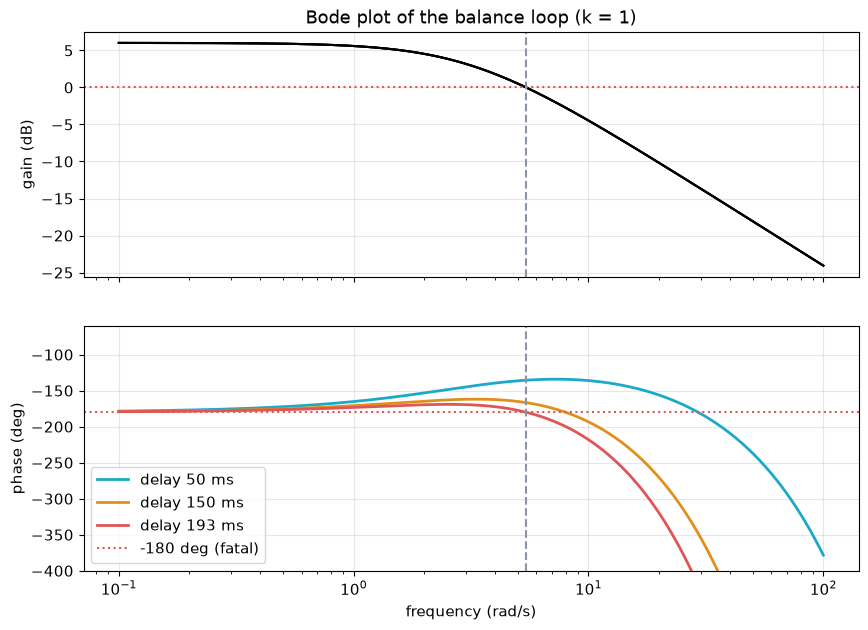

crossover: 5.42 rad/s = 0.86 Hz


In [12]:
k = 1.0
Om = np.logspace(-1, 2, 600)                  # 0.1 .. 100 rad/s
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
Wc = omega * np.sqrt((1 + k)**2 - 1)          # crossover (gain = 1), independent of the delay
tau_c = np.arctan(Wc / omega) / Wc            # critical delay: the margin is exactly zero
for d, c in [(0.05, CYAN), (0.15, AMBER), (tau_c, RED)]:
    L = omega * (1 + k) * np.exp(-1j * Om * d) / (1j * Om - omega)
    phase = np.unwrap(np.angle(L)) * 180 / np.pi
    phase -= 360 * np.round((phase[0] + 180) / 360)   # start the curve at -180 deg
    a1.semilogx(Om, 20 * np.log10(abs(L)), color="k", lw=1.5)
    a2.semilogx(Om, phase, color=c, lw=2, label=f"delay {d*1000:.0f} ms")
    pm = np.degrees(np.arctan(Wc / omega) - Wc * d)
    print(f"delay {d*1000:4.0f} ms: phase margin {pm:5.1f} deg")
a1.axhline(0, color=RED, ls=":"); a1.axvline(Wc, color=GREY, ls="--")
a1.set_ylabel("gain (dB)"); a1.set_title("Bode plot of the balance loop (k = 1)")
a2.axhline(-180, color=RED, ls=":", label="-180 deg (fatal)"); a2.axvline(Wc, color=GREY, ls="--")
a2.set_ylim(-400, -60); a2.set_ylabel("phase (deg)"); a2.set_xlabel("frequency (rad/s)"); a2.legend()
plt.show()
print(f"crossover: {Wc:.2f} rad/s = {Wc/2/np.pi:.2f} Hz")

**Reading the plot:** the gain curve (top) is the same for every delay; it crosses 0 dB at the dashed line. At that
frequency (bottom), every extra millisecond of delay pulls the phase down towards −180°. At the critical delay
(printed above, about **190 ms** for z = 1 m) the margin is gone, which is the same delay where the ringing in Part 7 stopped dying out.

**Two views, one fact:**
- **Time domain:** a late correction overshoots and the ringing grows.
- **Frequency domain:** the delay's phase lag eats the phase margin.

The ringing you saw at 150 ms is the *small margin* (printed above) made visible.

## Part 10: Taking a step

When the capture point leaves the reachable CoP region, the only way out is to **move the feet**: put a foot down
**on or beyond the capture point**. A step takes time (we assume 0.3 s), and the leg has a maximum reach (assumed 0.45 m).

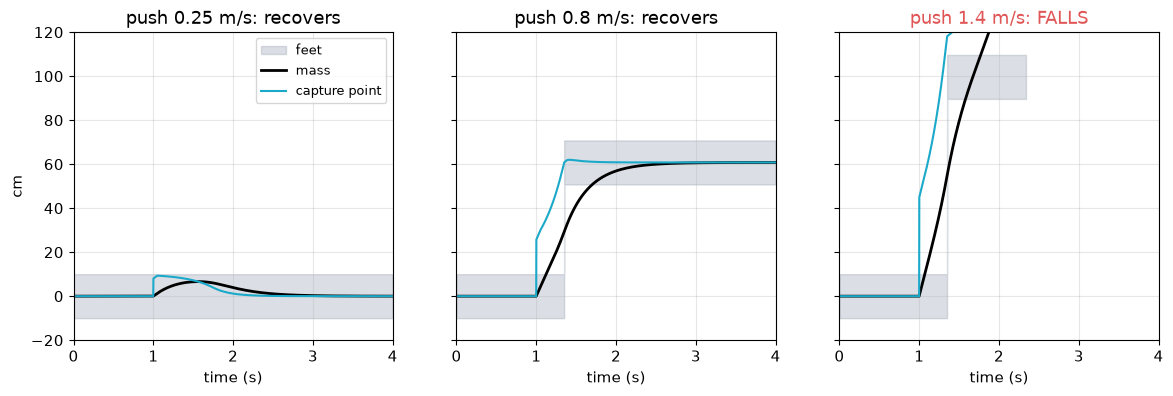

In [13]:
def simulate_step(push, delay=0.05, k=1.0, foot=0.10, step_time=0.3, reach=0.45, T=4.0):
    t = np.arange(0, T, dt)
    lag = int(round(delay / dt))
    x, v, c = 0.0, 0.0, 0.0          # c = centre of the current support (moves when we step)
    hist, X, XI, C = [], [], [], []
    step_at, stepped, fell = None, False, False
    for ti in t:
        if abs(ti - 1.0) < dt / 2:
            v += push
        hist.append(capture_point(x, v))
        xi = hist[-1 - lag] if len(hist) > lag else hist[0]
        # decide to step when the (seen) capture point is outside the feet
        if step_at is None and not stepped and abs(xi - c) > foot:
            step_at = ti + step_time
        if step_at is not None and ti >= step_at:
            # predict the capture point at landing and put the foot there, limited by the leg's reach
            c = x + np.clip(capture_point(x, v) - x, -reach, reach)
            step_at, stepped = None, True     # one step only, to keep it simple
        p = np.clip(c + (1 + k) * (xi - c), c - foot, c + foot)
        x, v = lip_step(x, v, p)
        X.append(x); XI.append(capture_point(x, v)); C.append(c)
        if abs(x - c) > 1.0:          # the mass is 1 m beyond the feet: it has fallen
            fell = True; break
    n = len(X)
    return t[:n], np.array(X), np.array(XI), np.array(C), fell

fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, push in zip(axs, [0.25, 0.8, 1.4]):
    t, X, XI, C, fell = simulate_step(push)
    ax.fill_between(t, (C - 0.10) * 100, (C + 0.10) * 100, color=GREY, alpha=0.3, label="feet")
    ax.plot(t, X * 100, "k", lw=2, label="mass")
    ax.plot(t, XI * 100, color=CYAN, lw=1.5, label="capture point")
    ax.set_title(f"push {push} m/s: " + ("FALLS" if fell else "recovers"), color=RED if fell else "k")
    ax.set_xlabel("time (s)"); ax.set_xlim(0, 4)
axs[0].set_ylabel("cm"); axs[0].legend(fontsize=9); axs[0].set_ylim(-20, 120); plt.show()

**Left:** the capture point stays inside the feet, so the ankles handle it. **Middle:** it leaves the feet, so a step
moves the support under it and the body recovers. **Right:** the capture point runs further than the leg can reach,
so the step lands short and it falls.

This is the logic of the three strategies in the video (ankles → hips → step → fall), in about 20 lines.

## Part 11: Playground

Change the numbers and run. Questions worth exploring:
1. With `delay = 0.15`, what is the largest push the ankles can handle? Compare with `delay = 0.05`.
2. Does a **taller** robot (bigger `z` in Part 1, then re-run all cells) tolerate more delay? Why? (Hint: $\omega$.)
3. With `delay = 0.15`, which gain `k` gives the calmest response?
4. In Part 10, how does a slower step (`step_time = 0.5`) change the largest recoverable push?

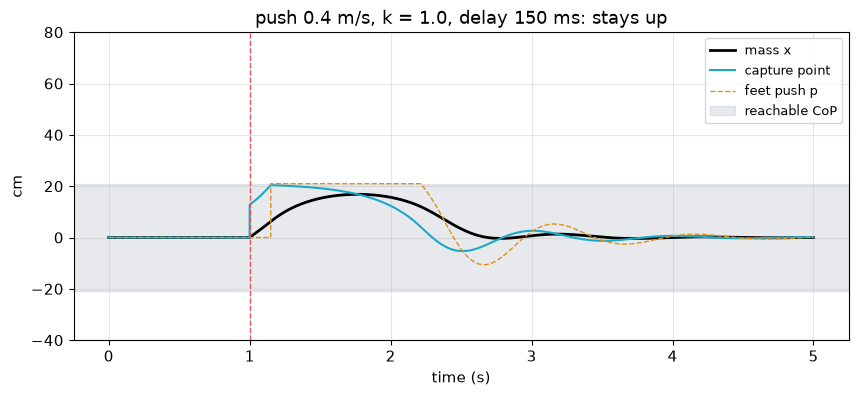

In [14]:
push, k, delay, foot = 0.4, 1.0, 0.15, 0.21

t, X, XI, P = simulate(push=push, k=k, delay=delay, foot=foot, T=5)
plt.plot(t, X * 100, "k", lw=2, label="mass x")
plt.plot(t, XI * 100, color=CYAN, lw=1.5, label="capture point")
plt.plot(t, P * 100, color=AMBER, lw=1, ls="--", label="feet push p")
plt.axhspan(-foot * 100, foot * 100, color=GREY, alpha=0.2, label="reachable CoP")
plt.axvline(1.0, color=RED, ls="--", lw=1)
fell = len(t) < len(np.arange(0, 5, dt))
plt.title(f"push {push} m/s, k = {k}, delay {delay*1000:.0f} ms: " + ("FELL" if fell else "stays up"))
plt.xlabel("time (s)"); plt.ylabel("cm"); plt.legend(fontsize=9); plt.ylim(-40, 80); plt.show()

### Where this connects to the video and the sources
- The model and the controller here are a simplified version of `clips/balance_sim.py`, which drives the robot you see in
  the video (MuJoCo only draws the body).
- Linear inverted pendulum: Kajita et al. 2001. Capture point: Pratt et al. 2006. Ankle and hip strategies in people:
  Horak & Nashner 1986. Details and caveats are in `docs/facts.md`.